In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",None)
pd.set_option("display.float_format","{:.2f}".format)

In [2]:
PROJECT_ROOT = Path.cwd().parent

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "SkyCity Auckland Restaurants & Bars.csv"

df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,212,118,141,9321.64,5188.46,6199.77,0.21,0.37,0.28,11,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.30
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,508,282,339,20548.60,11406.90,13712.55,0.25,0.41,0.28,16,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.30
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,537,298,358,21496.11,11928.94,14330.74,0.22,0.41,0.30,11,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.30
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,390,217,260,14149.20,7872.76,9432.80,0.24,0.44,0.33,3,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.30
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,436,242,291,14972.24,8310.28,9992.94,0.22,0.43,0.33,9,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.30


In [4]:
revenue_cols = [
    "InStoreRevenue",
    "UberEatsRevenue",
    "DoorDashRevenue",
    "SelfDeliveryRevenue"
]

profit_cols = [
    "InStoreNetProfit",
    "UberEatsNetProfit",
    "DoorDashNetProfit",
    "SelfDeliveryNetProfit"
]

order_cols = [
    "InStoreOrders",
    "UberEatsOrders",
    "DoorDashOrders",
    "SelfDeliveryOrders"
]

df["TotalRevenue"] = df[revenue_cols].sum(axis=1)
df["TotalNetProfit"] = df[profit_cols].sum(axis=1)

df["CalculatedTotalOrders"] = df[order_cols].sum(axis=1)

df["OverallProfitMargin"] = np.where(
    df["TotalRevenue"] > 0,
    df["TotalNetProfit"] / df["TotalRevenue"] * 100,
    np.nan
)

df["ProfitPerOrder"] = np.where(
    df["CalculatedTotalOrders"] > 0,
    df["TotalNetProfit"] / df["CalculatedTotalOrders"],
    np.nan
)

display(
    df[[
        "RestaurantName",
        "TotalRevenue",
        "TotalNetProfit",
        "OverallProfitMargin",
        "ProfitPerOrder"
    ]]
)

,RestaurantName,TotalRevenue,TotalNetProfit,OverallProfitMargin,ProfitPerOrder
0,Urban Burgers House,29371.96,7964.56,27.12,11.92
1,Urban Burgers Diner,56144.60,8775.70,15.63,6.32
2,King Burgers Eatery,68731.51,14403.26,20.96,8.39
3,Classic Burgers Tavern,39291.24,5266.83,13.40,4.86
4,Lucky Burgers Bistro,42238.20,6119.35,14.49,4.98
...,...,...,...,...,...
1691,Lotus Bistro,22309.47,6253.63,28.03,12.84
1692,Dragon Bistro,42255.20,10253.47,24.27,10.73
1693,Dragon Corner,33897.76,3670.65,10.83,4.84
1694,Golden Corner,40086.32,5625.93,14.03,5.19


In [5]:
channel_names = {
    "InStore": "In-Store",
    "UberEats": "Uber Eats",
    "DoorDash": "DoorDash",
    "SelfDelivery": "Self-Delivery"
}

channel_summary = []

for prefix, channel_name in channel_names.items():
    revenue = df[f"{prefix}Revenue"]
    profit = df[f"{prefix}NetProfit"]
    orders = df[f"{prefix}Orders"]
    
    total_revenue = revenue.sum()
    total_profit = profit.sum()
    total_orders = orders.sum()
    
    channel_summary.append({
        "Channel": channel_name,
        "Total Revenue": total_revenue,
        "Total Profit": total_profit,
        "Total Orders": total_orders,
        "Profit per Order": (
            total_profit / total_orders if total_orders > 0 else np.nan
        ),
        "Profit Margin (%)": (
            total_profit / total_revenue * 100
            if total_revenue > 0 else np.nan
        )
    })
    
channel_summary = pd.DataFrame(channel_summary)
display(channel_summary.round(2))

,Channel,Total Revenue,Total Profit,Total Orders,Profit per Order,Profit Margin (%)
0,In-Store,14284378.07,3828417.36,371391,10.31,26.80
1,Uber Eats,30816371.49,258488.08,800353,0.32,0.84
2,DoorDash,16789380.95,151122.25,436135,0.35,0.90
3,Self-Delivery,15849176.29,3628278.44,411255,8.82,22.89


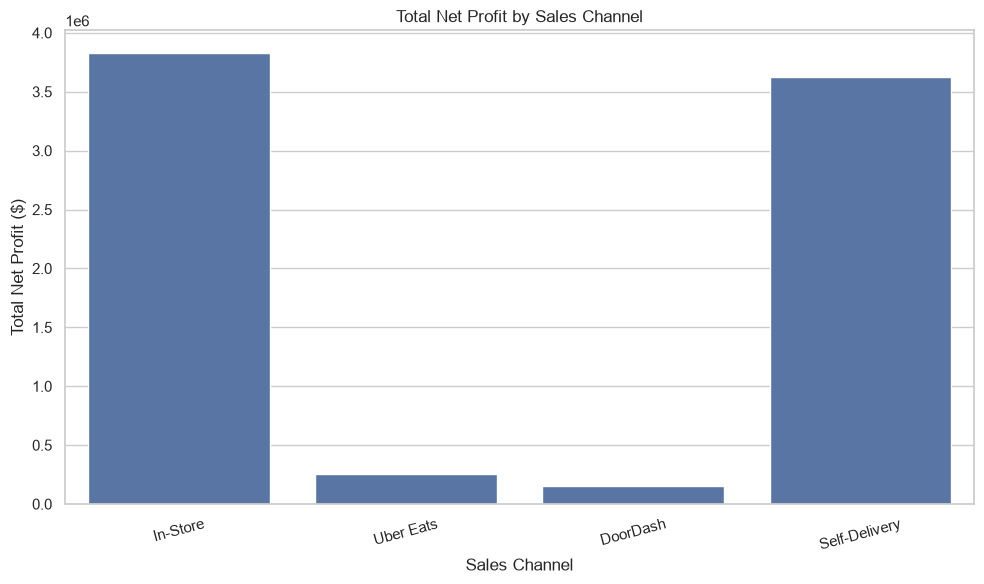

In [6]:
plt.figure(figsize=(10,6))

sns.barplot(
    data = channel_summary,
    x = "Channel",
    y = "Total Profit"
)

plt.title("Total Net Profit by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Net Profit ($)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

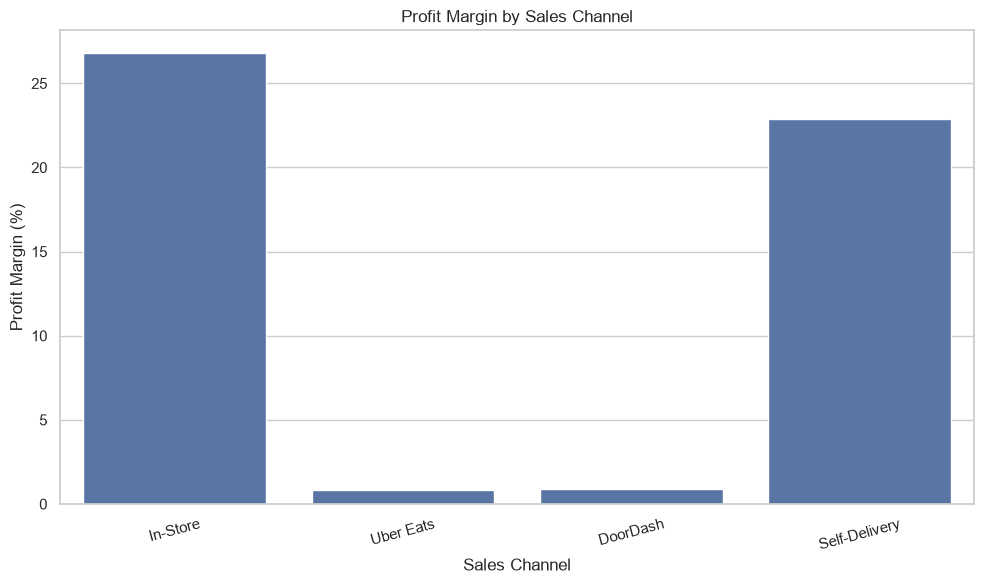

In [7]:
plt.figure(figsize=(10,6))

sns.barplot(
    data = channel_summary,
    x = "Channel",
    y = "Profit Margin (%)"
)

plt.title("Profit Margin by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [8]:
cuisine_analysis = (
    df.groupby("CuisineType")
    .agg(
        Restaurants = ("RestaurantID", "nunique"),
        TotalRevenue = ("TotalRevenue", "sum"),
        TotalProfit = ("TotalNetProfit", "sum"),
        AverageProfit = ("TotalNetProfit", "mean"),
        AverageMargin = ("OverallProfitMargin", "mean")
    ).sort_values("AverageMargin", ascending=False)
)

display(cuisine_analysis.round(2))

,Restaurants,TotalRevenue,TotalProfit,AverageProfit,AverageMargin
CuisineType,,,,,
Pizza,219,11045190.86,1599877.75,7305.38,14.84
Burgers,375,18771503.37,2327693.48,6207.18,12.87
Chinese,218,10013978.81,1012118.27,4642.74,10.64
Thai,120,5057515.22,427530.92,3562.76,9.16
Indian,329,13615825.12,1131201.93,3438.30,8.97
Japanese,120,5208643.91,442374.96,3686.46,8.64
Chicken Dishes,148,7106663.66,558387.64,3772.89,8.11
Kebabs/Mediterranean,167,6919985.85,367121.18,2198.33,6.18


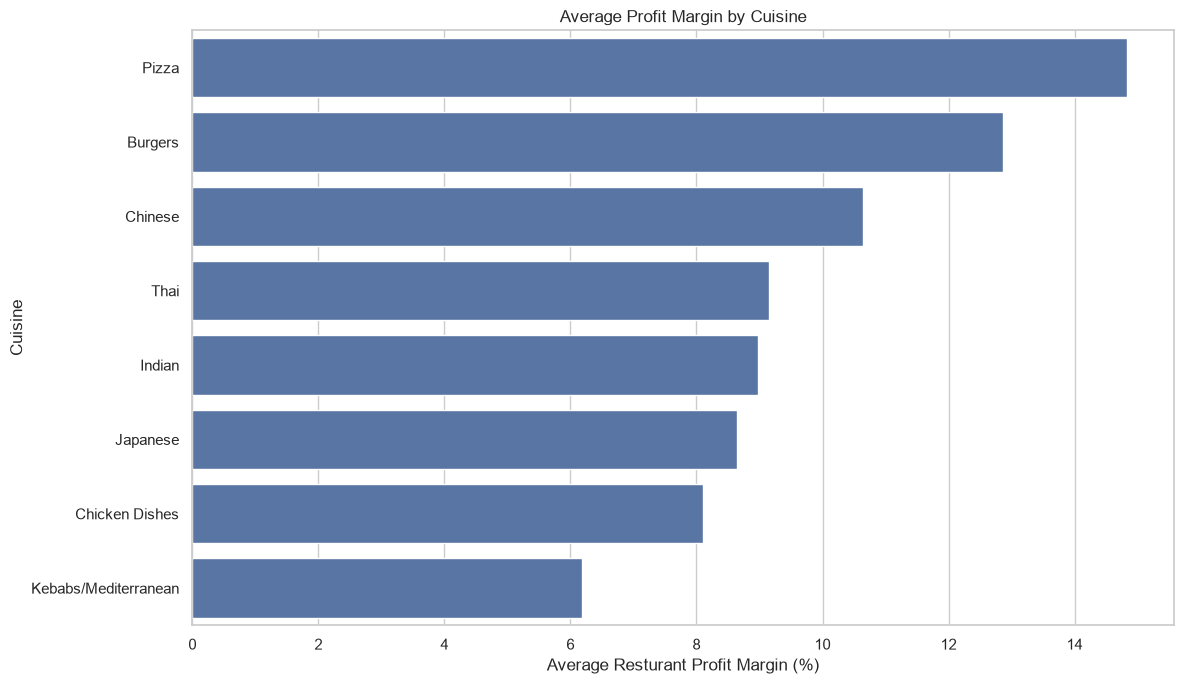

In [9]:
plt.figure(figsize=(12,7))

sns.barplot(
    data = cuisine_analysis.reset_index(),
    x = "AverageMargin",
    y = "CuisineType"
)

plt.title("Average Profit Margin by Cuisine")
plt.xlabel("Average Resturant Profit Margin (%)")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

In [10]:
segment_analysis = (
    df.groupby("Segment")
    .agg(
        Restaurants = ("RestaurantID", "nunique"),
        TotalRevenue = ("TotalRevenue", "sum"),
        TotalProfit = ("TotalNetProfit", "sum"),
        AverageProfit = ("TotalNetProfit", "mean"),
        AverageMargin = ("OverallProfitMargin", "mean")
    ).sort_values("AverageMargin", ascending= False)
)

display(segment_analysis.round(2))

,Restaurants,TotalRevenue,TotalProfit,AverageProfit,AverageMargin
Segment,,,,,
Ghost Kitchen,197,8030853.78,1783066.46,9051.10,22.03
Cafe,504,23247488.68,3770700.40,7481.55,15.92
QSR,543,23871097.27,3614317.10,6656.20,14.79
Full-service,452,22589867.07,-1301777.83,-2880.04,-5.92


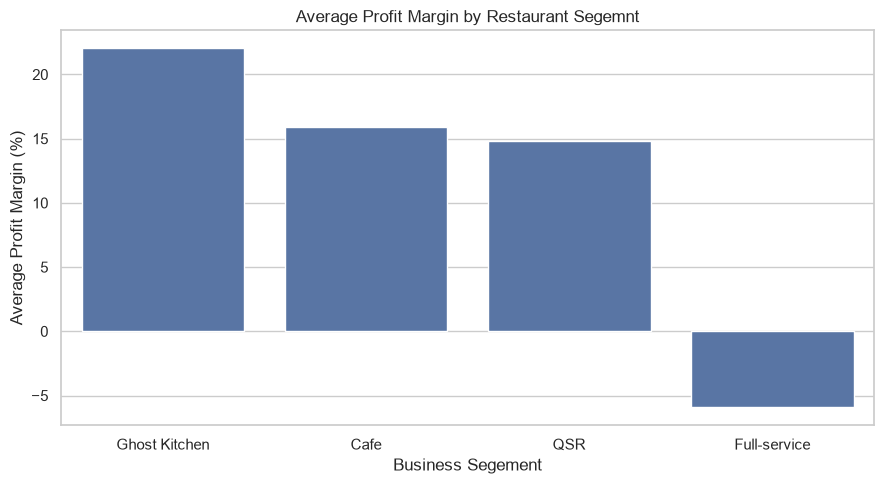

In [11]:
plt.figure(figsize=(9,5))

sns.barplot(
    data = segment_analysis.reset_index(),
    x = "Segment",
    y = "AverageMargin"
)

plt.title("Average Profit Margin by Restaurant Segemnt")
plt.xlabel("Business Segement")
plt.ylabel("Average Profit Margin (%)")
plt.tight_layout()
plt.show()

In [12]:
loss_making = df[df["TotalNetProfit"] < 0].copy()

print("Total restaurant:", len(df))
print("Loss-making restaurant:", len(loss_making))
print(
    "Loss-making percentage:",
    round(len(loss_making) / len(df) * 100, 2), "%"
)

display(
    loss_making[
        [
            "RestaurantID",
            "RestaurantName",
            "CuisineType",
            "Segment",
            "TotalRevenue",
            "TotalNetProfit",
            "OverallProfitMargin"
        ]
    ].sort_values("TotalNetProfit").head(10)
)

Total restaurant: 1696
Loss-making restaurant: 408
Loss-making percentage: 24.06 %


,RestaurantID,RestaurantName,CuisineType,Segment,TotalRevenue,TotalNetProfit,OverallProfitMargin
1244,25339,Ottoman Diner,Kebabs/Mediterranean,Full-service,81510.12,-10192.83,-12.50
885,25393,Tandoori Kitchen,Indian,Full-service,73812.75,-9974.52,-13.51
1067,25837,Spice Diner,Indian,Full-service,83654.68,-9840.65,-11.76
1649,25842,Lotus Tavern,Thai,Full-service,73264.00,-9224.14,-12.59
1269,25470,Greek House,Kebabs/Mediterranean,Full-service,73497.60,-9202.01,-12.52
1331,25692,Greek Grill,Kebabs/Mediterranean,Full-service,67380.56,-9024.43,-13.39
467,26035,Top Chicken Dishes Corner,Chicken Dishes,Full-service,82752.40,-8962.15,-10.83
1315,25447,Souvlaki Tavern,Kebabs/Mediterranean,Full-service,63752.04,-8948.12,-14.04
830,25541,Bombay House,Indian,Full-service,84393.20,-8905.84,-10.55
1284,26334,Ottoman Bistro,Kebabs/Mediterranean,Full-service,48478.68,-8562.72,-17.66


In [15]:
restaurant_ranking = df[
    [
        "RestaurantID",
        "RestaurantName",
        "CuisineType",
        "Segment",
        "TotalRevenue",
        "TotalNetProfit",
        "OverallProfitMargin"
    ]
].copy()

print("Bottom 10 by total profit")
display(
    restaurant_ranking
    .sort_values("TotalNetProfit", ascending=False)
    .head(10)
)

Bottom 10 by total profit


,RestaurantID,RestaurantName,CuisineType,Segment,TotalRevenue,TotalNetProfit,OverallProfitMargin
1551,25948,King Pizza Eatery,Pizza,Cafe,95963.98,27368.36,28.52
113,25573,Top Burgers Tavern,Burgers,Cafe,86382.94,21269.54,24.62
1538,25934,Urban Pizza Grill,Pizza,Cafe,85428.00,21101.73,24.70
1567,26524,Lucky Pizza Bistro,Pizza,Cafe,82467.79,21091.11,25.57
1143,25575,Red Cafe,Japanese,Ghost Kitchen,73449.75,20911.68,28.47
79,25418,Top Burgers Eatery,Burgers,Cafe,84025.89,20842.89,24.81
329,25598,Top Burgers Diner,Burgers,Cafe,86838.25,20828.26,23.99
1380,26574,Urban Pizza Tavern,Pizza,Cafe,93352.17,20827.71,22.31
1453,25298,Classic Pizza Eatery,Pizza,QSR,89660.30,20217.63,22.55
722,25356,Golden Bistro,Chinese,Ghost Kitchen,63181.84,19741.76,31.25


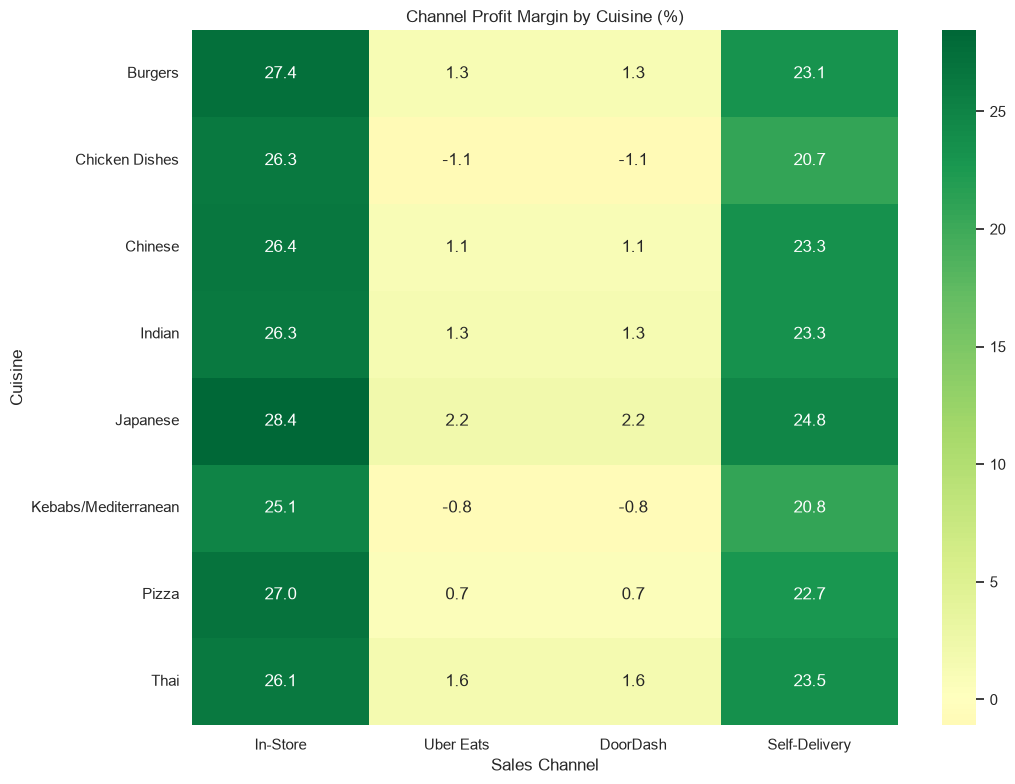

In [20]:
channel_profit_cols = {
    "In-Store": "InStoreNetProfit",
    "Uber Eats": "UberEatsNetProfit",
    "DoorDash": "DoorDashNetProfit",
    "Self-Delivery": "SelfDeliveryNetProfit"
}

channel_Revenue_cols = {
    "In-Store": "InStoreRevenue",
    "Uber Eats": "UberEatsRevenue",
    "DoorDash": "DoorDashRevenue",
    "Self-Delivery": "SelfDeliveryRevenue"
}

heatmap_data = {}

for channel in channel_names.values():
    prefix = {
        "In-Store": "InStore",
        "Uber Eats": "Uber Eats",
        "DoorDash": "DoorDash",
        "Self-Delivery": "SelfDelivery"
    }[channel]
    
    profit_col = channel_profit_cols[channel]
    revenue_col = channel_Revenue_cols[channel]
    
    cuisine_profit = df.groupby("CuisineType")[profit_col].sum()
    cuisine_revenue = df.groupby("CuisineType")[revenue_col].sum()
    
    heatmap_data[channel] = (
        cuisine_profit / cuisine_revenue.replace(0, np.nan) * 100
    )
    
heatmap_df = pd.DataFrame(heatmap_data)

plt.figure(figsize=(11, 8))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0
)

plt.title("Channel Profit Margin by Cuisine (%)")
plt.xlabel("Sales Channel")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()    

In [23]:
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "tables"

channel_summary.to_csv(
    OUTPUT_DIR / "channel_profitability.csv", index=False
)

cuisine_analysis.to_csv(
    OUTPUT_DIR / "cuisine_profitability.csv"
)

segment_analysis.to_csv(
    OUTPUT_DIR / "segment_profitability.csv"
)

restaurant_ranking.to_csv(
    OUTPUT_DIR / "reataurant_profitability.csv"
)

heatmap_df.to_csv(
    OUTPUT_DIR / "cuisine_channel_margin_heatmap.csv"
)
print("EDA tables saved to:", OUTPUT_DIR)

EDA tables saved to: c:\Users\ganesh\Desktop\All Projects\Restaurant Profitability Analysis ML\outputs\tables
